<a href="https://colab.research.google.com/github/quarcs-lab/geo4cambodia/blob/main/notebooks/geo4cambodia_quickstart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Load, link and build Cambodian indicators with `geo4cambodia`

Part of the [GeoDevelopment Observatory of Cambodia](https://quarcs-lab.github.io/geo4cambodia/).

This notebook is a hands-on tour of the observatory's data:

1. **Load data without the package**: every file is a plain URL
2. **Load data with the package** `geo4cambodia`
3. **Move data across scales**: districts, provinces, Global Data Lab regions and the country
4. **Link your own table** to the observatory's units, whatever the spelling
5. **Build a new indicator from a raster**
6. **Interpolate to a grid**, then **save** your dataset in the observatory's format

The companion notebook [`geometrics_convergence.ipynb`](https://colab.research.google.com/github/quarcs-lab/geo4cambodia/blob/main/notebooks/geometrics_convergence.ipynb) analyses the same data with the [geometrics](https://quarcs-lab.github.io/geometrics/) package.

## 0. Setup

In Google Colab the next cell installs the package (a few seconds: Colab already has its dependencies). Locally, `uv sync` has installed it already.

In [1]:
import importlib.util

if importlib.util.find_spec("geo4cambodia") is None:
    !pip install -q "geo4cambodia[raster]" mapclassify

In [2]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

## 1. Load data without the package

Every published file is a plain URL, so pandas, geopandas, R, Stata or Excel can read it directly. Three kinds of files matter:

- **`data/<scale>/<dataset>.csv`**: the indicators, as a panel with one row per unit (`geo_id`) and year
- **`geo/units.csv`**: names, parent units and the original source codes of every unit
- **`geo/boundaries/<scale>.geojson`**: polygons, keyed by the same `geo_id`

In [3]:
BASE = "https://raw.githubusercontent.com/quarcs-lab/geo4cambodia/main/"

gdppc = pd.read_csv(BASE + "data/district/gdppc.csv")          # 202 districts x 33 years
units = pd.read_csv(BASE + "geo/units.csv")                     # 245 units at 4 scales
districts = gpd.read_file(BASE + "geo/boundaries/district.geojson")

gdppc.head()

,geo_id,year,GID_2,y,ln_y,trend6_ln_y,trend100_ln_y,trend400_ln_y
0,KH-01-01,1990,KHM.1.1_2,676.0,6.516193,6.545359,6.504154,6.428658
1,KH-01-01,1991,KHM.1.1_2,711.0,6.566672,6.565005,6.517225,6.462579
2,KH-01-01,1992,KHM.1.1_2,651.0,6.478509,6.579986,6.530417,6.496720
3,KH-01-01,1993,KHM.1.1_2,1026.0,6.933423,6.585900,6.544344,6.531558
4,KH-01-01,1994,KHM.1.1_2,625.0,6.437752,6.562111,6.559102,6.567528


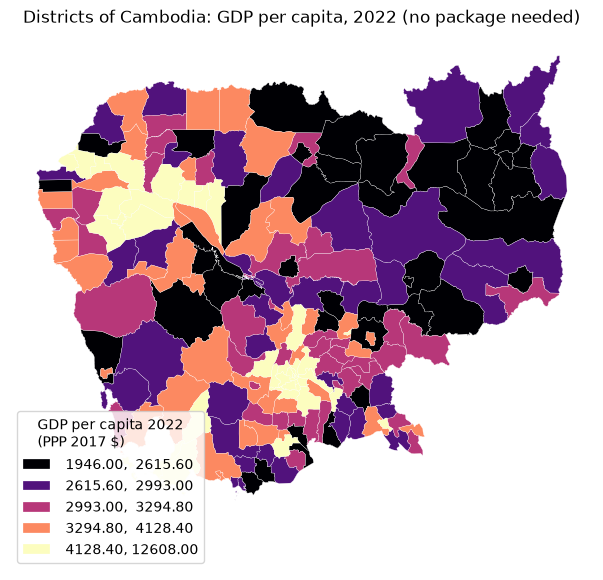

In [4]:
# Names come from geo/units.csv; every row also carries the ids of the units it lies in
names = units.loc[units["scale"] == "district", ["geo_id", "name", "province_id"]]
gdppc_2022 = districts.merge(gdppc[gdppc["year"] == 2022], on="geo_id").merge(names.drop(columns="name"), on="geo_id")

ax = gdppc_2022.plot(column="y", cmap="magma", scheme="quantiles", k=5, legend=True,
                     legend_kwds={"title": "GDP per capita 2022\n(PPP 2017 $)", "loc": "lower left"},
                     edgecolor="white", linewidth=0.2, figsize=(8, 7))
ax.set_axis_off()
ax.set_title("Districts of Cambodia: GDP per capita, 2022 (no package needed)");

## 2. Load data with the package

The package does the same in one line, and more: it lists the datasets, describes their variables, filters years and variables, reshapes, and attaches boundaries.

In [5]:
import geo4cambodia as geo

geo.datasets()

,dataset,scale,title,first_year,last_year,variables,csv,parquet
0,gdppc,district,Estimated GDP per capita,1990,2022,5,data/district/gdppc.csv,data/district/gdppc.parquet
1,env,province,"Population, night-time lights, electricity-bas...",1986,2023,6,data/province/env.csv,data/province/env.parquet
2,hdi,gdl,"Human development, income, night-time lights a...",2013,2019,9,data/gdl/hdi.csv,data/gdl/hdi.parquet


In [6]:
geo.dictionary("env")      # every variable: description, unit, aggregation rule, source

,variable,description,unit,role,aggregation,source
0,geo_id,Province geo ID,,id,,
1,year,Year,,time,,
2,shapeISO,ISO 3166-2 province code (geoBoundaries),,source_key,,geoBoundaries
3,total_GlobPOP_Density,Zonal sum of gridded population density,"people per km², summed over cells",variable,sum,Liu et al. (2024)
4,total_GlobPOP_Count,Zonal sum of gridded population count,people,variable,sum,Liu et al. (2024)
5,total_VNL,Zonal sum of NPP-VIIRS-like night-time lights,"nW/cm²/sr, summed over cells",variable,sum,Chen et al. (2021)
6,total_EGDP,Zonal sum of electricity-based revised real GDP,"as in source, summed over cells",variable,sum,Chen et al. (2022)
7,total_NPP,Zonal sum of net primary productivity (missing...,"as in source, summed over cells",variable,sum,Robinson et al. (2018)
8,total_GHAP,Zonal sum of PM2.5 concentration (GHAP),"µg/m³, summed over cells",variable,sum,Wei et al. (2023)


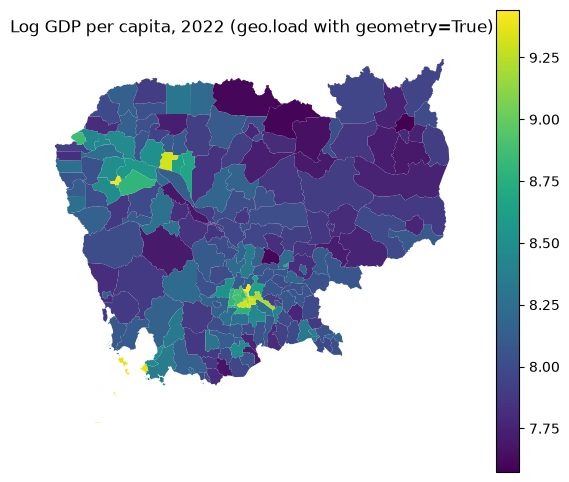

In [7]:
gdf = geo.load("gdppc", years=2022, geometry=True)     # a GeoDataFrame, ready to map
ax = gdf.plot(column="ln_y", cmap="viridis", legend=True, figsize=(7, 6))
ax.set_axis_off()
ax.set_title("Log GDP per capita, 2022 (geo.load with geometry=True)");

In [8]:
# A window of years and a few variables; or one row per unit with one column per year
lights = geo.load("env", years=(2012, 2023), variables=["total_VNL", "total_GlobPOP_Count"])
wide = geo.load("gdppc", wide="y")
lights.head(3), wide.iloc[:3, :6]

(  geo_id  year  total_GlobPOP_Count   total_VNL
 0  KH-01  2012        738193.882353  107.327094
 1  KH-01  2013        749276.094118  208.466166
 2  KH-01  2014        760791.301961  401.618624,
      geo_id   y1990   y1991   y1992   y1993   y1994
 0  KH-01-01   676.0   711.0   651.0  1026.0   625.0
 1  KH-01-02  1075.0  1106.0  1342.0  2074.0  1324.0
 2  KH-01-03  1899.0  1957.0  2003.0  3091.0  1976.0)

In [9]:
geo.units("province").head(3)     # names, parents, and the codes each source uses (GADM, geoBoundaries, GDL)

,geo_id,scale,name,parent_id,country_id,province_id,district_id,gdl_id,gid,shapeISO,shapeID,GDLcode,name_gadm,name_geoboundaries,name_gdl,area_km2
0,KH-01,province,Banteay Meanchey,KH,KH,KH-01,<NA>,KH-GDL-01,KHM.1_1,KH-1,KHM-ADM1-1590546715-B14,KHMr101,BântéayMéanchey,Bantey Meanchey,<NA>,6144.52
1,KH-02,province,Battambang,KH,KH,KH-02,<NA>,KH-GDL-13,KHM.2_1,KH-2,KHM-ADM1-1590546715-B25,KHMr113,Batdâmbâng,Battambang,<NA>,12105.39
2,KH-03,province,Kampong Cham,KH,KH,KH-03,<NA>,KH-GDL-02,KHM.3_1,KH-3,KHM-ADM1-1590546715-B17,KHMr102,KâmpóngCham,Kampong Cham,<NA>,4550.95


## 3. Move data across scales

Each scale nests in the coarser ones, and each variable's metadata says how it may be aggregated (`sum` for totals, `weighted_mean:POP` for HDI, `none` for logs and per-capita values without population).

In [10]:
geo.scales()          # the registry of scales

,label,kind,parent,children,id_pattern,example,status
scale,,,,,,,
country,Country,admin,NaN,NaN,^KH$,KH,active
province,Province,admin,country,NaN,^KH-\d{2}$,KH-16,active
district,District,admin,province,NaN,^KH-\d{2}-\d{2}$,KH-16-01,active
commune,Commune,admin,district,NaN,^KH-\d{2}-\d{2}-\d{2}$,KH-16-01-01,planned
gdl,Global Data Lab region,grouping,country,province,^KH-GDL-\d{2}$,KH-GDL-02,active
grid10k,10 km grid cell,grid,NaN,NaN,^KH-G10K-r\d{3}c\d{3}$,KH-G10K-r012c034,planned


In [11]:
env = geo.load("env", years=2020)
by_gdl = geo.aggregate(env, to="gdl", dataset="env")             # 25 provinces -> 17 GDL regions
national = geo.aggregate(env, to="country", dataset="env")      # -> Cambodia
national[["geo_id", "year", "total_GlobPOP_Count", "total_VNL", "n_units"]]

,geo_id,year,total_GlobPOP_Count,total_VNL,n_units
0,KH,2020,1.640704e+07,35138.563094,25


`geo.combine()` loads several datasets at one scale and aggregates the finer ones on the way. Here, province remote-sensing totals meet Global Data Lab's HDI, and give a new indicator, lights per person:

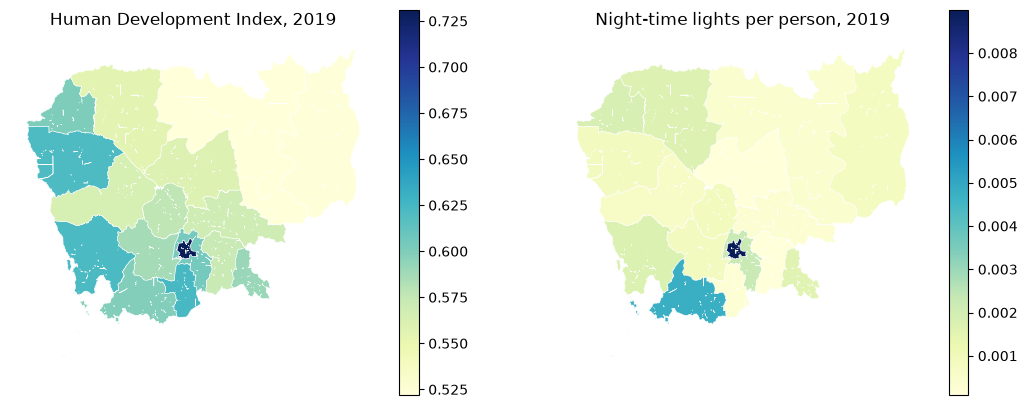

In [12]:
panel = geo.combine(["env", "hdi"], scale="gdl", years=(2013, 2019))
panel["lights_per_person"] = panel["total_VNL"] / panel["total_GlobPOP_Count"]

latest = geo.boundaries("gdl").merge(panel[panel["year"] == 2019], on="geo_id")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col, title in zip(axes, ["HDI", "lights_per_person"], ["Human Development Index", "Night-time lights per person"]):
    latest.plot(column=col, cmap="YlGnBu", legend=True, ax=ax, edgecolor="white", linewidth=0.4)
    ax.set_title(f"{title}, 2019"); ax.set_axis_off()

In [13]:
latest[["HDI", "lights_per_person"]].corr()

,HDI,lights_per_person
HDI,1.000000,0.763661
lights_per_person,0.763661,1.000000


## 4. Link your own table

Tables from reports and ministries identify units by name, spelled in many ways. `geo.link()` attaches the observatory's `geo_id`. It ignores accents, case, spaces and punctuation, and tries every name and code column in `geo.units()`.

The values below are **made up** for the demonstration; replace them with your own data.

In [14]:
mine = pd.DataFrame({
    "Province": ["BântéayMéanchey", "Battambang", "KAMPONG CHAM", "Phnom Penh", "Siemréab", "Bantey Meanchey"],
    "year":     [2020, 2020, 2020, 2020, 2020, 2021],
    "clinics":  [41, 77, 63, 120, 58, 43],          # illustrative values
})
mine = geo.link(mine, scale="province", on="Province")
mine

,geo_id,Province,year,clinics
0,KH-01,BântéayMéanchey,2020,41
1,KH-02,Battambang,2020,77
2,KH-03,KAMPONG CHAM,2020,63
3,KH-16,Phnom Penh,2020,120
4,KH-21,Siemréab,2020,58
5,KH-01,Bantey Meanchey,2021,43


In [15]:
geo.check(mine, scale="province")        # [] = a valid panel: known ids, one row per unit and year

[]

A typo stops with a suggestion instead of silently dropping the row:

In [16]:
try:
    geo.link(pd.DataFrame({"Province": ["Kampott"]}), scale="province", on="Province", key="name")
except ValueError as err:
    print(err)

1 value(s) of 'Province' match no province 'name': 'Kampott' (did you mean 'Kampot'?). Fix them, e.g. df['Province'] = df['Province'].replace({...}), or pass errors='warn'.


## 5. Build a new indicator from a raster

`geo.zonal()` summarises any GeoTIFF (for example an export from Google Earth Engine, or a WorldPop population grid) over the units of a scale. As a self-contained example, we compute a raster of **distance to Phnom Penh**, a simple proxy of market access, and average it over districts.

In [17]:
import rasterio
from rasterio.transform import from_bounds

x0, y0, x1, y1 = geo.boundaries("country").total_bounds
nx, ny = 800, 600                                            # about 600 m pixels
lon = np.linspace(x0, x1, nx); lat = np.linspace(y1, y0, ny)
LON, LAT = np.meshgrid(lon, lat)
pp_lat, pp_lon = np.radians(11.5564), np.radians(104.9282)     # Phnom Penh
dlat, dlon = np.radians(LAT) - pp_lat, np.radians(LON) - pp_lon
km = 2 * 6371 * np.arcsin(np.sqrt(np.sin(dlat / 2) ** 2 + np.cos(pp_lat) * np.cos(np.radians(LAT)) * np.sin(dlon / 2) ** 2))

with rasterio.open("distance_to_phnom_penh.tif", "w", driver="GTiff", width=nx, height=ny, count=1,
                   dtype="float32", crs="EPSG:4326", transform=from_bounds(x0, y0, x1, y1, nx, ny)) as dst:
    dst.write(km.astype("float32"), 1)

access = geo.zonal("distance_to_phnom_penh.tif", scale="district", stats=["mean", "max"], name="dist_pp_km")
access.head()

,geo_id,dist_pp_km_mean,dist_pp_km_max
0,KH-01-01,337.179117,358.340240
1,KH-01-02,299.096224,323.965851
2,KH-01-03,327.391902,346.203217
3,KH-01-04,339.072084,349.083618
4,KH-01-05,307.251698,324.874512


Is distance to the capital associated with income? Join the new indicator to the GDP panel:

correlation: -0.31


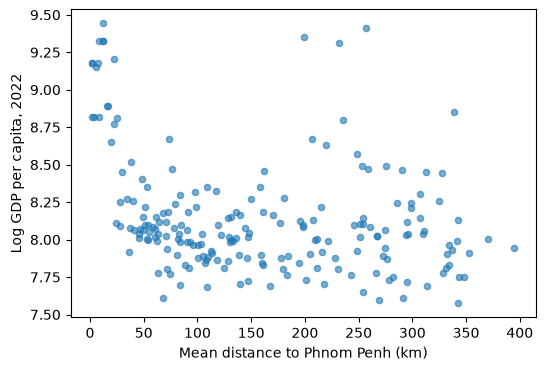

In [18]:
d = geo.load("gdppc", years=2022).merge(access, on="geo_id")
ax = d.plot.scatter(x="dist_pp_km_mean", y="ln_y", alpha=0.6, figsize=(6, 4))
ax.set_xlabel("Mean distance to Phnom Penh (km)"); ax.set_ylabel("Log GDP per capita, 2022")
print(f"correlation: {d['dist_pp_km_mean'].corr(d['ln_y']):.2f}")

## 6. Interpolate to a grid and save

Grids, watersheds or old boundaries do not nest in the administrative hierarchy. `geo.overlay()` moves data onto them by area weights. Totals (`extensive`) are split by area; rates (`intensive`) are area-weighted means.

provinces: 16,407,036  grid: 16,407,036


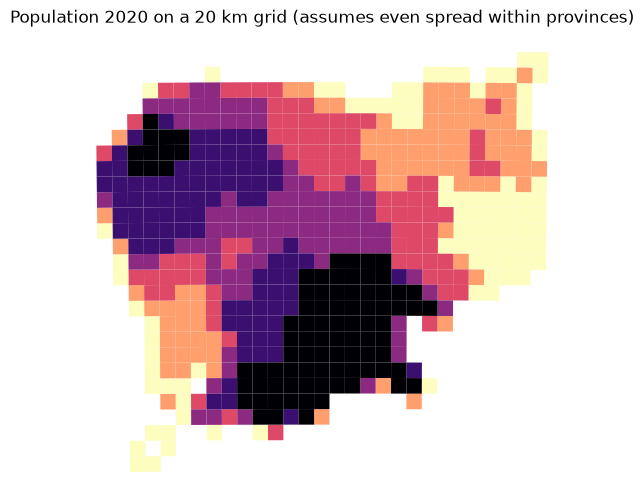

In [19]:
from shapely.geometry import box

country = geo.boundaries("country").to_crs("EPSG:32648")       # UTM 48N, metres
gx0, gy0, gx1, gy1 = country.total_bounds
cells = [box(x, y, x + 20_000, y + 20_000) for x in np.arange(gx0, gx1, 20_000) for y in np.arange(gy0, gy1, 20_000)]
grid = gpd.GeoDataFrame({"cell": [f"c{i}" for i in range(len(cells))]}, geometry=cells, crs="EPSG:32648")
grid = grid[grid.intersects(country.geometry.iloc[0])].to_crs("EPSG:4326")

pop = geo.load("env", years=2020, variables=["total_GlobPOP_Count"])
on_grid = geo.overlay(pop, grid, extensive=["total_GlobPOP_Count"], id_col="cell")
print(f"provinces: {pop['total_GlobPOP_Count'].sum():,.0f}  grid: {on_grid['total_GlobPOP_Count'].sum():,.0f}")

ax = grid.merge(on_grid.rename(columns={"geo_id": "cell"}), on="cell").plot(
    column="total_GlobPOP_Count", cmap="magma_r", scheme="quantiles", k=6, figsize=(7, 6))
ax.set_axis_off(); ax.set_title("Population 2020 on a 20 km grid (assumes even spread within provinces)");

Finally, save your indicator exactly like the published datasets: CSV, Parquet and a Frictionless datapackage describing every variable. It is then easy to share, reload or contribute to the observatory ([CONTRIBUTING_DATA.md](https://github.com/quarcs-lab/geo4cambodia/blob/main/CONTRIBUTING_DATA.md)).

In [20]:
access["year"] = 2024
geo.save(access[["geo_id", "year", "dist_pp_km_mean", "dist_pp_km_max"]], "market_access", scale="district",
         directory="my_data", title="Distance to Phnom Penh",
         description="Mean and maximum straight-line distance from each district to Phnom Penh.",
         variables={"dist_pp_km_mean": {"description": "Mean distance to Phnom Penh", "unit": "km", "aggregation": "none"},
                    "dist_pp_km_max": {"description": "Maximum distance to Phnom Penh", "unit": "km", "aggregation": "max"}})

wrote my_data/data/district/market_access.csv, my_data/data/district/market_access.parquet and my_data/metadata/market_access.datapackage.json


{'name': 'market_access',
 'title': 'Distance to Phnom Penh',
 'description': 'Mean and maximum straight-line distance from each district to Phnom Penh.',
 'version': '1.0.0',
 'licenses': [{'name': 'CC-BY-4.0'}],
 'sources': [],
 'geo:categories': [],
 'geo:notes': [],
 'resources': [{'name': 'market_access-district',
   'path': 'https://raw.githubusercontent.com/quarcs-lab/geo4cambodia/main/data/district/market_access.csv',
   'format': 'csv',
   'mediatype': 'text/csv',
   'encoding': 'utf-8',
   'geo:scale': 'district',
   'geo:period': [2024, 2024],
   'geo:path': 'data/district/market_access.csv',
   'geo:parquet': 'data/district/market_access.parquet',
   'schema': {'primaryKey': ['geo_id', 'year'],
    'fields': [{'name': 'geo_id',
      'type': 'string',
      'description': 'District ID',
      'geo:role': 'id',
      'constraints': {'required': True, 'pattern': '^KH-\\d{2}-\\d{2}$'}},
     {'name': 'year',
      'type': 'integer',
      'description': 'Year',
      'geo:role

## Next steps

- Analyse these data with **geometrics**: [`geometrics_convergence.ipynb`](https://colab.research.google.com/github/quarcs-lab/geo4cambodia/blob/main/notebooks/geometrics_convergence.ipynb)
- The full guide: [how the data infrastructure works](https://github.com/quarcs-lab/geo4cambodia/blob/main/docs/data-infrastructure.md)
- Every function has help: `help(geo.link)`